Dataset loaded successfully!


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
Dataset Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Missing values before cleaning:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Missing values after cleaning:
sepal_length       0
sepal_width        0
petal_length       0
petal_width        0
species            0
average_feature    0
size_category      0
dtype: int64

Total Samples: 149
Average Sepal Length: 5.84
Average Sepal Width: 3.06
Average Petal Length: 3.75
Overall Feature Average: 3.46

Size Category Distribution:
size_category
Medium    88
Large     40
Small     21
Name: count, dtype: int64


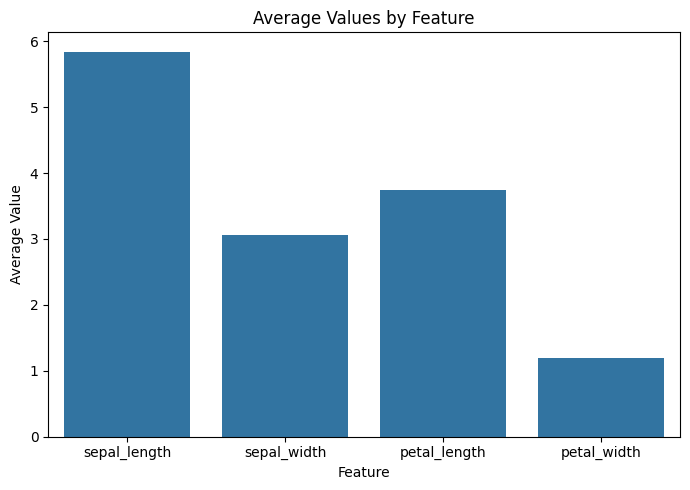

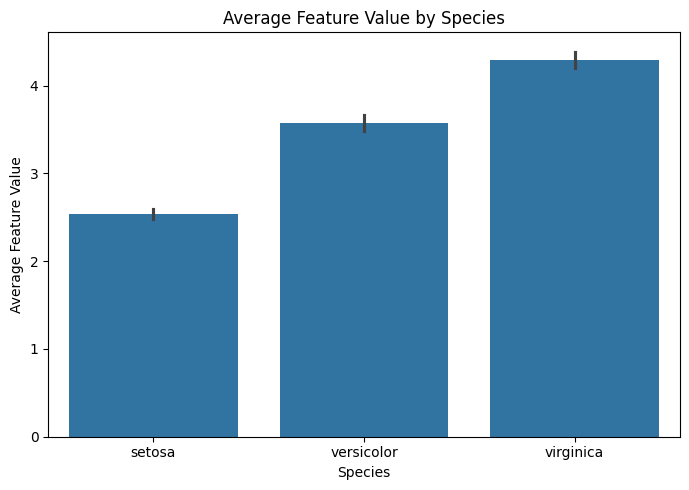

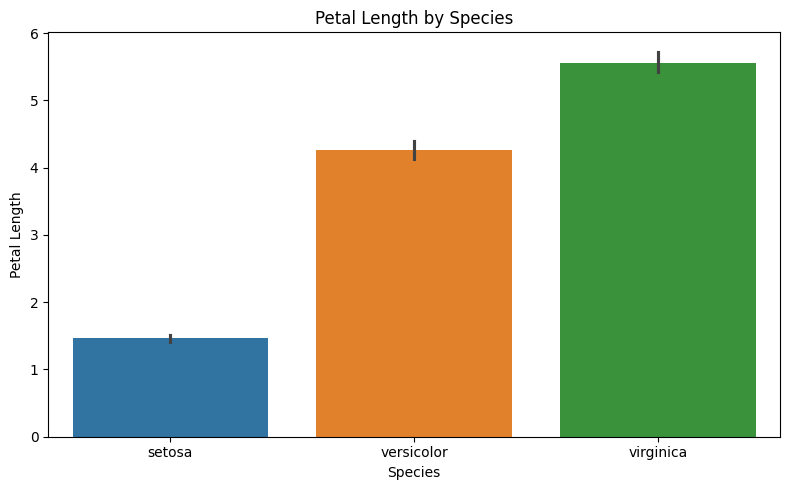

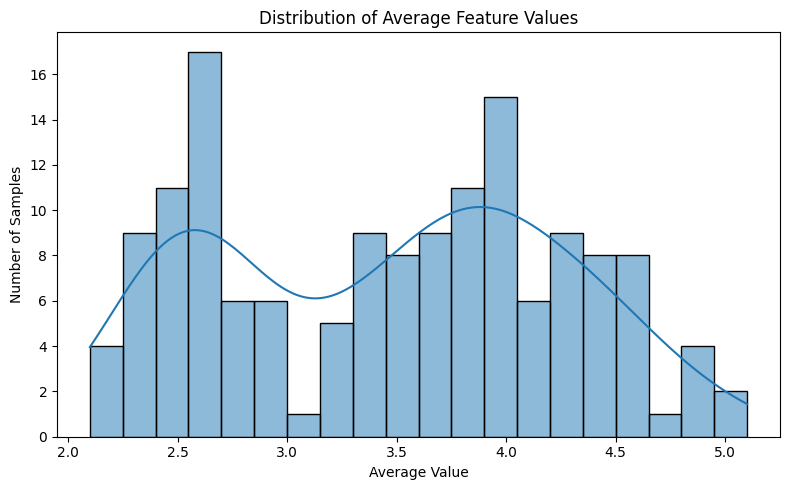


Cleaned dataset exported successfully!
File: iris_performance_cleaned.xlsx


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load a permanently available, guaranteed valid dataset directly from Seaborn
df = sns.load_dataset('iris')

print("Dataset loaded successfully!")
display(df.head())

# Dataset information
df.info()

print("Dataset Shape:", df.shape)
display(df.describe())

# Data cleaning
print("\nMissing values before cleaning:")
print(df.isnull().sum())

df = df.drop_duplicates()

# rename columns to lowercase clean format
df.columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

# Add average feature score and size category
df['average_feature'] = df[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']].mean(axis=1)
df['size_category'] = df['average_feature'].apply(lambda x: 'Large' if x >= 4.0 else ('Medium' if x >= 2.5 else 'Small'))

print("\nMissing values after cleaning:")
print(df.isnull().sum())

# Statistical analysis
print("\nTotal Samples:", len(df))
print("Average Sepal Length:", round(df['sepal_length'].mean(), 2))
print("Average Sepal Width:", round(df['sepal_width'].mean(), 2))
print("Average Petal Length:", round(df['petal_length'].mean(), 2))
print("Overall Feature Average:", round(df['average_feature'].mean(), 2))

print("\nSize Category Distribution:")
print(df['size_category'].value_counts())

# Visualization 1: Average values by feature
feature_means = df[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']].mean()
plt.figure(figsize=(7, 5))
sns.barplot(x=feature_means.index, y=feature_means.values)
plt.title('Average Values by Feature')
plt.xlabel('Feature')
plt.ylabel('Average Value')
plt.tight_layout()
plt.show()

# Visualization 2: Performance by Species
plt.figure(figsize=(7, 5))
sns.barplot(data=df, x='species', y='average_feature')
plt.title('Average Feature Value by Species')
plt.xlabel('Species')
plt.ylabel('Average Feature Value')
plt.tight_layout()
plt.show()

# Visualization 3: Feature Distribution by Species
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='species', y='petal_length', hue='species')
plt.title('Petal Length by Species')
plt.xlabel('Species')
plt.ylabel('Petal Length')
plt.tight_layout()
plt.show()

# Visualization 4: Distribution of Average Feature value
plt.figure(figsize=(8, 5))
sns.histplot(df['average_feature'], bins=20, kde=True)
plt.title('Distribution of Average Feature Values')
plt.xlabel('Average Value')
plt.ylabel('Number of Samples')
plt.tight_layout()
plt.show()

# Export cleaned dataset
df.to_excel('iris_performance_cleaned.xlsx', index=False)

print("\nCleaned dataset exported successfully!")
print("File: iris_performance_cleaned.xlsx")

In [2]:
%pip install pandas matplotlib seaborn openpyxl